# Software inventory coverage

Audit a small bill of materials for missing package metadata.

A component inventory supports dependency review. Measure coverage separately for name, version and licence. A licence string merely records a declaration, so provenance and legal review remain distinct from field completeness.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Run the local experiment

All records used below belong to the small fixture supplied by the example.

field coverage {'name': np.float64(1.0), 'version': np.float64(0.75), 'licence': np.float64(0.75)}
complete records 2 of 4


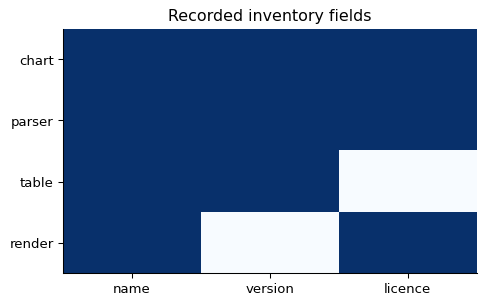

In [2]:
components = [
    {"name": "chart", "version": "2.1", "licence": "MIT"},
    {"name": "parser", "version": "1.4", "licence": "BSD-3-Clause"},
    {"name": "table", "version": "1.0"},
    {"name": "render", "licence": "Apache-2.0"},
]
fields = ["name", "version", "licence"]
present = np.array([[bool(r.get(k)) for k in fields] for r in components])
coverage = present.mean(0)
print("field coverage", dict(zip(fields, coverage)))
print("complete records", present.all(1).sum(), "of", len(components))
assert np.array_equal(present.sum(0), [4, 3, 3])
fig, ax = plt.subplots(figsize=(5, 3.1), constrained_layout=True)
ax.imshow(present, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set(
    xticks=range(len(fields)),
    xticklabels=fields,
    yticks=range(len(components)),
    yticklabels=[r["name"] for r in components],
    title="Recorded inventory fields",
)
plt.show()

## Interpreting the result

The matrix shows field presence in a teaching fixture. Full CycloneDX validation requires the selected schema version and its component structure.

## Exercise

Add an explicit source field and recompute the proportion of complete records.

## References

[CycloneDX, specification overview](https://cyclonedx.org/specification/overview/)

[NIST Cybersecurity Framework 2.0](https://doi.org/10.6028/NIST.CSWP.29)